# AI Resume Screening System

End-to-end notebook: load resumes, clean text, engineer features, train and compare
classifiers, evaluate the best model, and build a resume-to-job-description
matching function. Artifacts (`clf.pkl`, `tfidf.pkl`, `encoder.pkl`) are exported
at the end so a Flask app can reuse the exact same preprocessing and model.

Dataset: [Kaggle Resume Dataset](https://www.kaggle.com/datasets/gauravduttakiit/resume-dataset)
(`UpdatedResumeDataSet.csv`) with columns `Category` and `Resume`.

## Phase 1 — Setup

Import the libraries we need for data handling, text cleaning, feature
extraction, modeling, and visualization. Download the NLTK corpora
(`stopwords`, `punkt`) required for text cleaning, then load the dataset
into a pandas DataFrame.

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import re
import pickle

# NLTK for stopword removal
import nltk
from nltk.corpus import stopwords

# scikit-learn for encoding, features, modeling, evaluation
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_STATE = 42

%matplotlib inline
sns.set_style("whitegrid")

In [2]:
# Download required NLTK corpora (safe to re-run; no-op if already present)
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\radha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\radha\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\radha\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
# Load the dataset
DATA_PATH = "UpdatedResumeDataSet.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \nMay 2013 to May 2017 B.E ...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \n MCA YMCAUST, Faridabad..."


## Phase 2 — Exploratory Data Analysis

Get a feel for the dataset: its shape, a preview of the rows, how many
resumes exist per category, and whether there are any nulls or duplicate
rows that need to be handled before modeling.

In [4]:
print("Shape:", df.shape)
df.head()

Shape: (962, 2)


,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \nMay 2013 to May 2017 B.E ...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \n MCA YMCAUST, Faridabad..."


In [5]:
# Distribution of resumes per category
category_counts = df['Category'].value_counts()
category_counts

Category
Java Developer               84
Testing                      70
DevOps Engineer              55
Python Developer             48
Web Designing                45
HR                           44
Hadoop                       42
Data Science                 40
Mechanical Engineer          40
Sales                        40
Operations Manager           40
ETL Developer                40
Blockchain                   40
Arts                         36
Database                     33
Health and fitness           30
Electrical Engineering       30
PMO                          30
Business Analyst             28
DotNet Developer             28
Automation Testing           26
Network Security Engineer    25
Civil Engineer               24
SAP Developer                24
Advocate                     20
Name: count, dtype: int64

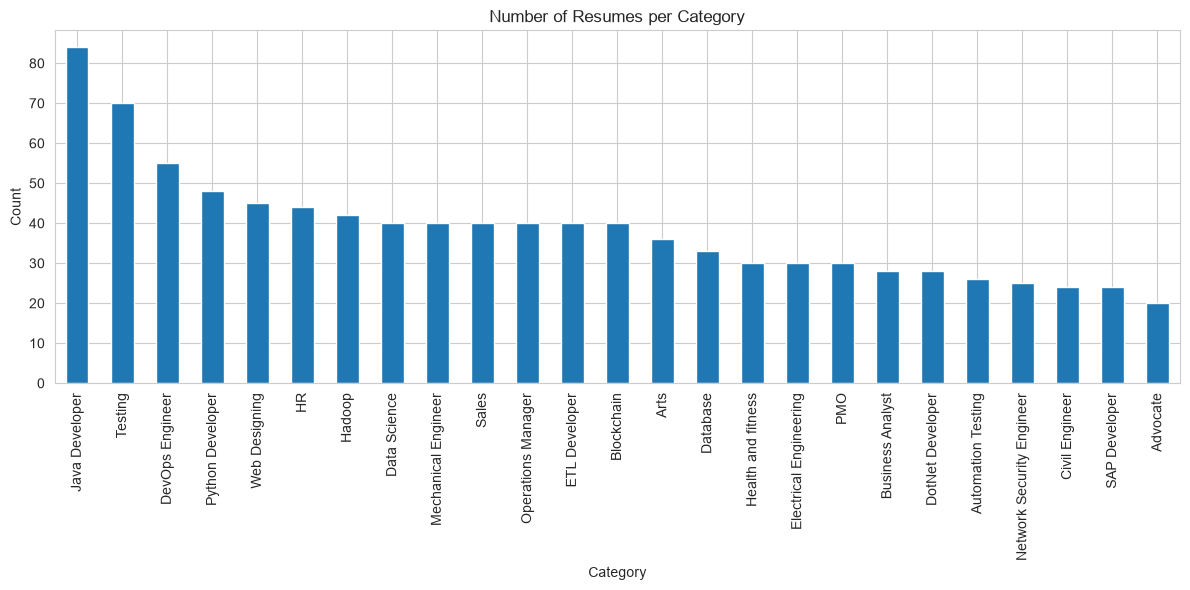

In [6]:
# Bar plot of category distribution
plt.figure(figsize=(12, 6))
category_counts.plot(kind='bar')
plt.title("Number of Resumes per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

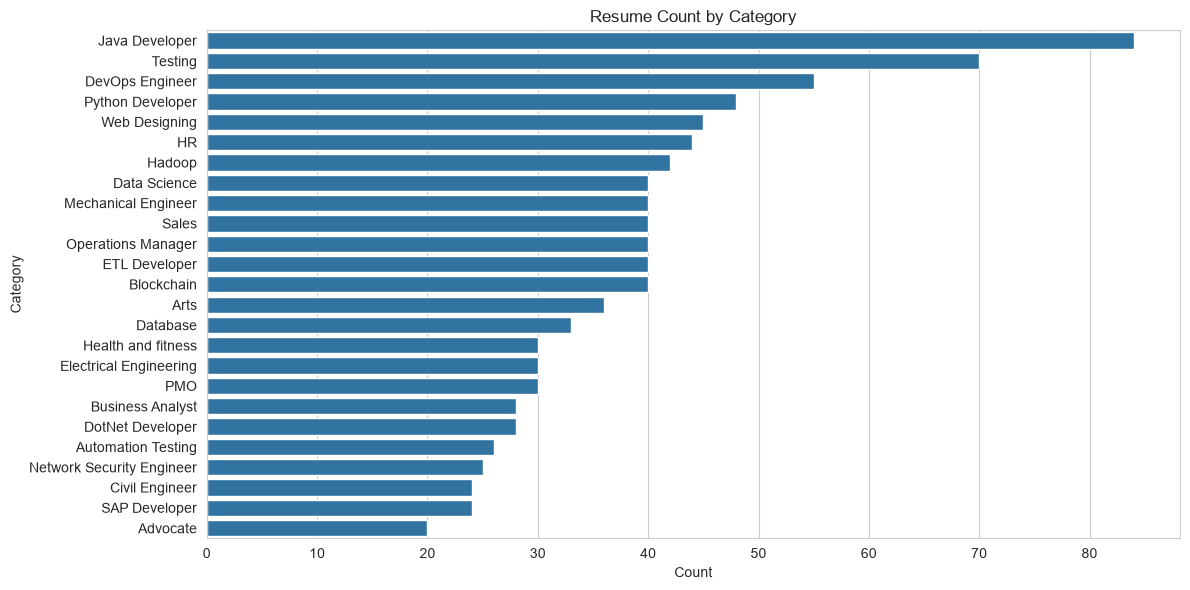

In [7]:
# Countplot (seaborn) of category distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='Category', order=category_counts.index)
plt.title("Resume Count by Category")
plt.xlabel("Count")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [8]:
# Check for null values
print("Null values per column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Null values per column:
Category    0
Resume      0
dtype: int64

Duplicate rows: 796


In [9]:
# Drop duplicates and nulls if any were found (keeps the notebook safe to re-run)
df = df.dropna().drop_duplicates().reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Shape after cleaning: (166, 2)


## Phase 3 — Text Cleaning

Define a single `clean_resume(text)` function that normalizes raw resume
text: strips URLs, `RT`/`cc` tokens, hashtags, mentions, punctuation, and
non-ASCII characters, collapses extra whitespace, lowercases everything,
and removes English stopwords.

This function is kept **standalone and dependency-light** (just `re` +
NLTK stopwords) so it can be copy-imported into the Flask app and produce
identical preprocessing at inference time.

In [10]:
# English stopword set (computed once, reused inside clean_resume)
STOPWORDS = set(stopwords.words('english'))


def clean_resume(text):
    """Clean raw resume/job-description text for TF-IDF vectorization.

    Steps: remove URLs, RT/cc tokens, hashtags, mentions, punctuation,
    non-ASCII characters, and extra whitespace; lowercase; strip English
    stopwords. Kept dependency-light so the Flask app can reuse it as-is.
    """
    text = str(text)

    text = re.sub(r'http\S+\s*', ' ', text)          # URLs
    text = re.sub(r'RT|cc', ' ', text)               # RT / cc tokens
    text = re.sub(r'#\S+', ' ', text)                # hashtags
    text = re.sub(r'@\S+', ' ', text)                # mentions
    text = re.sub(r'[^\x00-\x7f]', ' ', text)        # non-ASCII characters
    text = re.sub(r'[%s]' % re.escape(
        '!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'), ' ', text)  # punctuation
    text = re.sub(r'\s+', ' ', text)                 # extra whitespace

    text = text.lower().strip()

    # Remove stopwords
    tokens = text.split()
    tokens = [word for word in tokens if word not in STOPWORDS]

    return ' '.join(tokens)


# Quick sanity check
sample = "RT @recruiter: Check this #DataScientist resume: http://example.com/cv (5+ yrs, Python/SQL)!"
clean_resume(sample)

'check resume 5 yrs python sql'

In [11]:
# Apply cleaning to every resume
df['cleaned_resume'] = df['Resume'].apply(clean_resume)
df[['Resume', 'cleaned_resume']].head()

,Resume,cleaned_resume
0,Skills * Programming Languages: Python (pandas...,skills programming languages python pandas num...
1,Education Details \nMay 2013 to May 2017 B.E ...,education details may 2013 may 2017 b e uit rg...
2,"Areas of Interest Deep Learning, Control Syste...",areas interest deep learning control system de...
3,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...,skills r python sap hana tableau sap hana sql ...
4,"Education Details \n MCA YMCAUST, Faridabad...",education details mca ymcaust faridabad haryan...


## Phase 4 — Label Encoding

Convert the string `Category` labels into integer labels with
`LabelEncoder` so they can be used by the classifiers. Save the fitted
encoder as `encoder.pkl` and keep a human-readable `{label: category}`
mapping for decoding predictions later.

In [12]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['Category'])

# Readable mapping: encoded label -> original category name
category_mapping = dict(zip(le.transform(le.classes_), le.classes_))
category_mapping

{np.int64(0): 'Advocate',
 np.int64(1): 'Arts',
 np.int64(2): 'Automation Testing',
 np.int64(3): 'Blockchain',
 np.int64(4): 'Business Analyst',
 np.int64(5): 'Civil Engineer',
 np.int64(6): 'Data Science',
 np.int64(7): 'Database',
 np.int64(8): 'DevOps Engineer',
 np.int64(9): 'DotNet Developer',
 np.int64(10): 'ETL Developer',
 np.int64(11): 'Electrical Engineering',
 np.int64(12): 'HR',
 np.int64(13): 'Hadoop',
 np.int64(14): 'Health and fitness',
 np.int64(15): 'Java Developer',
 np.int64(16): 'Mechanical Engineer',
 np.int64(17): 'Network Security Engineer',
 np.int64(18): 'Operations Manager',
 np.int64(19): 'PMO',
 np.int64(20): 'Python Developer',
 np.int64(21): 'SAP Developer',
 np.int64(22): 'Sales',
 np.int64(23): 'Testing',
 np.int64(24): 'Web Designing'}

In [13]:
# Persist the fitted encoder for reuse at inference time
with open('encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

print("Saved encoder.pkl")
df[['Category', 'label']].drop_duplicates().sort_values('label').reset_index(drop=True)

Saved encoder.pkl


,Category,label
0,Advocate,0
1,Arts,1
2,Automation Testing,2
3,Blockchain,3
4,Business Analyst,4
5,Civil Engineer,5
6,Data Science,6
7,Database,7
8,DevOps Engineer,8
9,DotNet Developer,9


## Phase 5 — Feature Extraction

Convert the cleaned resume text into numeric features with a
`TfidfVectorizer` (English stopwords removed again at the vectorizer
level, capped at 1500 features). Save the fitted vectorizer as
`tfidf.pkl` so the same vocabulary/IDF weights are reused for inference
and job-description matching.

In [14]:
tfidf = TfidfVectorizer(stop_words='english', max_features=1500)

X = tfidf.fit_transform(df['cleaned_resume'])
y = df['label'].values

print("Feature matrix shape:", X.shape)

Feature matrix shape: (166, 1500)


In [15]:
# Persist the fitted vectorizer for reuse at inference time
with open('tfidf.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

print("Saved tfidf.pkl")

Saved tfidf.pkl


## Phase 6 — Train/Test Split + Modeling

Split the TF-IDF features into train/test sets (80/20, stratified on the
label so every category is represented proportionally in both splits).
Train three different classifiers — K-Nearest Neighbors (wrapped in
`OneVsRestClassifier`), `LinearSVC`, and `RandomForestClassifier` — and
compare their accuracy and per-class classification reports.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (132, 1500)
Test shape: (34, 1500)


In [17]:
models = {
    "KNeighborsClassifier (OvR)": OneVsRestClassifier(KNeighborsClassifier()),
    "LinearSVC": LinearSVC(random_state=RANDOM_STATE, max_iter=10000),
    "RandomForestClassifier": RandomForestClassifier(random_state=RANDOM_STATE),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = {"model": model, "accuracy": acc, "y_pred": y_pred}

    print(f"===== {name} =====")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(
        y_test, y_pred,
        labels=np.unique(y),
        target_names=le.inverse_transform(np.unique(y)),
        zero_division=0
    ))
    print()

===== KNeighborsClassifier (OvR) =====
Accuracy: 0.7941
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         2
                     Arts       1.00      1.00      1.00         1
       Automation Testing       0.25      1.00      0.40         1
               Blockchain       1.00      1.00      1.00         1
         Business Analyst       0.50      1.00      0.67         1
           Civil Engineer       1.00      1.00      1.00         1
             Data Science       0.67      1.00      0.80         2
                 Database       1.00      1.00      1.00         2
          DevOps Engineer       0.00      0.00      0.00         1
         DotNet Developer       0.67      1.00      0.80         2
            ETL Developer       1.00      1.00      1.00         1
   Electrical Engineering       1.00      1.00      1.00         1
                       HR       1.00      1.00      1.00         2
     

===== RandomForestClassifier =====
Accuracy: 0.7353
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         2
                     Arts       0.50      1.00      0.67         1
       Automation Testing       0.50      1.00      0.67         1
               Blockchain       0.00      0.00      0.00         1
         Business Analyst       0.00      0.00      0.00         1
           Civil Engineer       1.00      1.00      1.00         1
             Data Science       1.00      1.00      1.00         2
                 Database       1.00      1.00      1.00         2
          DevOps Engineer       1.00      1.00      1.00         1
         DotNet Developer       1.00      0.50      0.67         2
            ETL Developer       1.00      1.00      1.00         1
   Electrical Engineering       0.00      0.00      0.00         1
                       HR       0.33      1.00      0.50         2
         

## Phase 7 — Evaluation

Pick the best-performing model by test accuracy, visualize its
performance with a confusion matrix heatmap, and persist it as
`clf.pkl` — the model the Flask app will load for live predictions.

In [18]:
best_model_name = max(results, key=lambda name: results[name]["accuracy"])
best_model = results[best_model_name]["model"]
best_y_pred = results[best_model_name]["y_pred"]

print(f"Best model: {best_model_name} (accuracy = {results[best_model_name]['accuracy']:.4f})")

Best model: LinearSVC (accuracy = 0.8529)


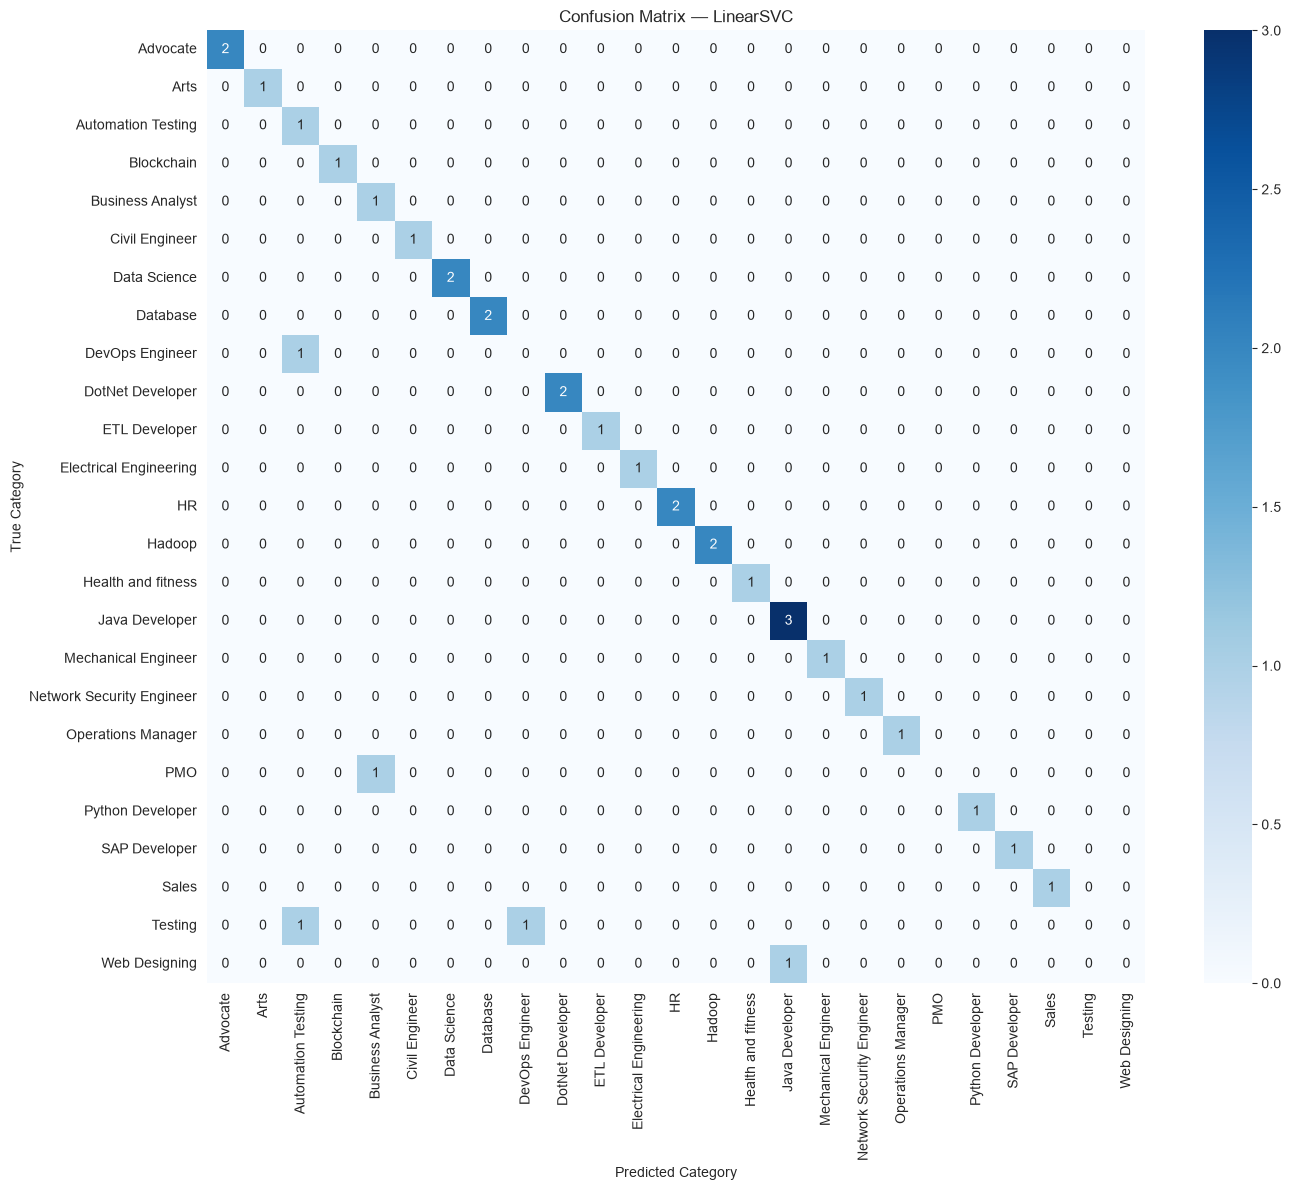

In [19]:
cm = confusion_matrix(y_test, best_y_pred, labels=np.unique(y))
labels_readable = le.inverse_transform(np.unique(y))

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels_readable, yticklabels=labels_readable
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("True Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
# Persist the best model for reuse at inference time
with open('clf.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print(f"Saved clf.pkl ({best_model_name})")

Saved clf.pkl (LinearSVC)


## Phase 8 — Job Description Match (Screening Logic)

Beyond category prediction, recruiters want a **match score** between a
candidate's resume and a specific job description. `match_score` cleans
both texts with the same `clean_resume` function, TF-IDF transforms them
together using the fitted vectorizer, and returns their cosine
similarity as a 0–100 percentage.

In [21]:
def match_score(resume_text, jd_text):
    """Return the cosine-similarity match between a resume and a job
    description as a 0-100 percentage, using the fitted TF-IDF vectorizer.
    """
    cleaned_resume_text = clean_resume(resume_text)
    cleaned_jd_text = clean_resume(jd_text)

    vectors = tfidf.transform([cleaned_resume_text, cleaned_jd_text])
    similarity = cosine_similarity(vectors[0], vectors[1])[0][0]

    return round(similarity * 100, 2)

In [22]:
# Demo: one sample resume vs. a sample job description
sample_resume = df['Resume'].iloc[0]

sample_jd = """
We are looking for a Data Scientist with strong experience in Python,
machine learning, SQL, and data visualization. The ideal candidate has
worked with pandas, scikit-learn, and has exposure to deep learning
frameworks such as TensorFlow or PyTorch. Experience with NLP and
model deployment is a plus.
"""

score = match_score(sample_resume, sample_jd)
print(f"Match score: {score}%")

Match score: 14.13%


## Phase 9 — Inference Demo

Simulate what the Flask app will do at prediction time: take one raw
resume string, run it through `clean_resume` -> the saved TF-IDF
vectorizer -> the saved classifier, decode the predicted label back to
a readable category name, and confirm all three artifacts were saved
successfully.

In [23]:
def predict_category(raw_resume_text):
    """End-to-end inference: raw resume text -> predicted category name."""
    cleaned = clean_resume(raw_resume_text)
    features = tfidf.transform([cleaned])
    predicted_label = best_model.predict(features)[0]
    predicted_category = le.inverse_transform([predicted_label])[0]
    return predicted_category


# Try it on a raw resume from the dataset
raw_sample = df['Resume'].iloc[10]
predicted = predict_category(raw_sample)

print("Raw resume (first 300 chars):\n", raw_sample[:300], "...\n")
print("Predicted Category:", predicted)
print("Actual Category:", df['Category'].iloc[10])

Raw resume (first 300 chars):
 TECHNICAL SKILLS â¢ Typewriting â¢ TORA â¢ SPSSEducation Details 
January 2017 MBA  Chidambaram, Tamil Nadu SNS College of Engineering
January 2014 HSC   at SAV Higher Secondary School
 MBA   SNS College of Engineering
 SSLC Finance  at Kamaraj Matriculation School
HR 


Skill Details 
Human reso ...

Predicted Category: HR
Actual Category: HR


In [24]:
# Confirm all three artifacts were saved
import os

for artifact in ['clf.pkl', 'tfidf.pkl', 'encoder.pkl']:
    exists = os.path.exists(artifact)
    size = os.path.getsize(artifact) if exists else 0
    print(f"{artifact}: {'OK' if exists else 'MISSING'} ({size} bytes)")

clf.pkl: OK (300991 bytes)
tfidf.pkl: OK (55922 bytes)
encoder.pkl: OK (633 bytes)
